In [1]:
import sqlite3
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_style('whitegrid')
%matplotlib inline

In [2]:
# Connect to the database
conn = sqlite3.connect('../data/anomaly_scores_test.db')

# Load data into a pandas DataFrame
df = pd.read_sql_query('SELECT * FROM anomaly_scores', conn)

print(f"Total commits: {len(df)}")
df.head()

Total commits: 185


,commit_node,commit_swhid,large_addition,large_deletion,large_modification,large_moves,time_of_day,author_tod,author_tod_global,committer_tod,...,newcomer_committer,account_age_author,account_age_committer,repository_dormancy,sensitive_file,prebuilt_file,ownership_score_json,ownership_has_unknown,total_score,weighted_score
0,4587386,swh:1:rev:b77999b3f9db098bb1f99fa6fe9f26add249...,1.0,0.0,0.000000,0.0,0.526582,0.213063,0.213063,0.521108,...,0.0,1.000000,0.000000,1.0,0.0,0.0,{},0,0.399171,0.399171
1,4587387,swh:1:rev:8af820967469e2e79c5a7b8e84c35c39427c...,1.0,0.0,0.000000,0.0,0.532447,0.213063,0.213063,0.542311,...,0.0,0.064677,0.000000,1.0,0.0,0.0,{},0,0.348159,0.348159
2,4587388,swh:1:rev:31aa25543cc7406f86e3e786e6b64ad2e73a...,0.0,0.0,0.284722,0.0,0.452693,0.213063,0.213063,0.450738,...,0.0,0.754778,0.000000,1.0,0.0,0.0,"{""Code/Day 1_Data PreProcessing.md"":0.33333333...",1,0.253428,0.253428
3,4587389,swh:1:rev:5d67810c1498082e7bb262cf6397d7861dfd...,0.0,1.0,0.000000,0.0,0.482810,0.518387,0.518387,0.476829,...,0.0,0.000000,0.000000,1.0,0.0,0.0,{},0,0.327049,0.327049
4,4587390,swh:1:rev:8ff8bff9ad83fe985f21be653b31e81c0459...,0.0,0.0,0.284722,0.0,0.482810,0.213063,0.213063,0.213063,...,1.0,0.449221,0.527774,1.0,0.0,0.0,"{""Code/Day 1_Data PreProcessing.md"":0.33333333...",1,0.289147,0.289147


In [3]:
# df_sus = pd.read_sql_query('SELECT * FROM anomaly_scores WHERE commit_swhid in ("swh:1:rev:847047cf7f81ab08352038b2204f0e7633449580", "swh:1:rev:6e344066a0464814a27fbd7ca8422f473956a803")', conn)
# df_sus

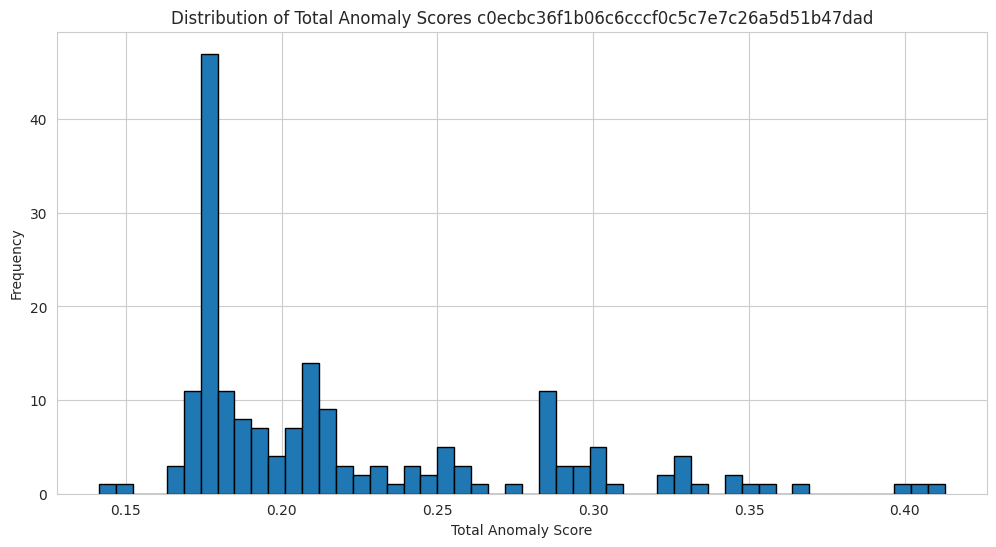

In [4]:
# Distribution of total scores
plt.figure(figsize=(12, 6))
plt.hist(df['weighted_score'], bins=50, edgecolor='black')
plt.xlabel('Total Anomaly Score')
plt.ylabel('Frequency')
plt.title('Distribution of Total Anomaly Scores c0ecbc36f1b06c6cccf0c5c7e7c26a5d51b47dad')
plt.show()

In [5]:
# Top 10 most anomalous commits
top_anomalies = df.nlargest(10, 'weighted_score')[['commit_swhid', 'weighted_score']]
print("Top 10 Most Anomalous Commits:")
print(top_anomalies)

Top 10 Most Anomalous Commits:
                                          commit_swhid  weighted_score
59   swh:1:rev:349b365c8674626a484c1d1f8d8418882ca5...        0.412779
47   swh:1:rev:837b30215535b44ba18e51df944c51c5cfbe...        0.402025
0    swh:1:rev:b77999b3f9db098bb1f99fa6fe9f26add249...        0.399171
69   swh:1:rev:759577ab016598c294f8772fd1361063e3fa...        0.367484
68   swh:1:rev:792dd344e1f117d77402d1cd7f0b9a3fa2b7...        0.354715
1    swh:1:rev:8af820967469e2e79c5a7b8e84c35c39427c...        0.348159
54   swh:1:rev:edadfc4233007431b1d1fda5dbf467343566...        0.346653
51   swh:1:rev:619b5277ea2d0c875478683160947b840cea...        0.343926
82   swh:1:rev:1eb2eafb4198ebbe31e25477dd15ed1126fa...        0.331666
154  swh:1:rev:ab1ebc4fc719711ec527480ad3f6859a9af6...        0.327374


In [6]:
# Display top 5% of commits by weighted_score in descending order
threshold = df['weighted_score'].quantile(0.95)
top_5_percent = df[df['weighted_score'] >= threshold].sort_values('weighted_score', ascending=False)

print(f"Threshold for top 5%: {threshold}")
print(f"Number of commits in top 5%: {len(top_5_percent)}")
print("\nTop 5% commits by weighted_score:")
top_5_percent[['commit_swhid', 'weighted_score', 'total_score']]

Threshold for top 5%: 0.3273741772758107
Number of commits in top 5%: 12

Top 5% commits by weighted_score:


,commit_swhid,weighted_score,total_score
59,swh:1:rev:349b365c8674626a484c1d1f8d8418882ca5...,0.412779,0.412779
47,swh:1:rev:837b30215535b44ba18e51df944c51c5cfbe...,0.402025,0.402025
0,swh:1:rev:b77999b3f9db098bb1f99fa6fe9f26add249...,0.399171,0.399171
69,swh:1:rev:759577ab016598c294f8772fd1361063e3fa...,0.367484,0.367484
68,swh:1:rev:792dd344e1f117d77402d1cd7f0b9a3fa2b7...,0.354715,0.354715
1,swh:1:rev:8af820967469e2e79c5a7b8e84c35c39427c...,0.348159,0.348159
54,swh:1:rev:edadfc4233007431b1d1fda5dbf467343566...,0.346653,0.346653
51,swh:1:rev:619b5277ea2d0c875478683160947b840cea...,0.343926,0.343926
82,swh:1:rev:1eb2eafb4198ebbe31e25477dd15ed1126fa...,0.331666,0.331666
154,swh:1:rev:ab1ebc4fc719711ec527480ad3f6859a9af6...,0.327374,0.327374


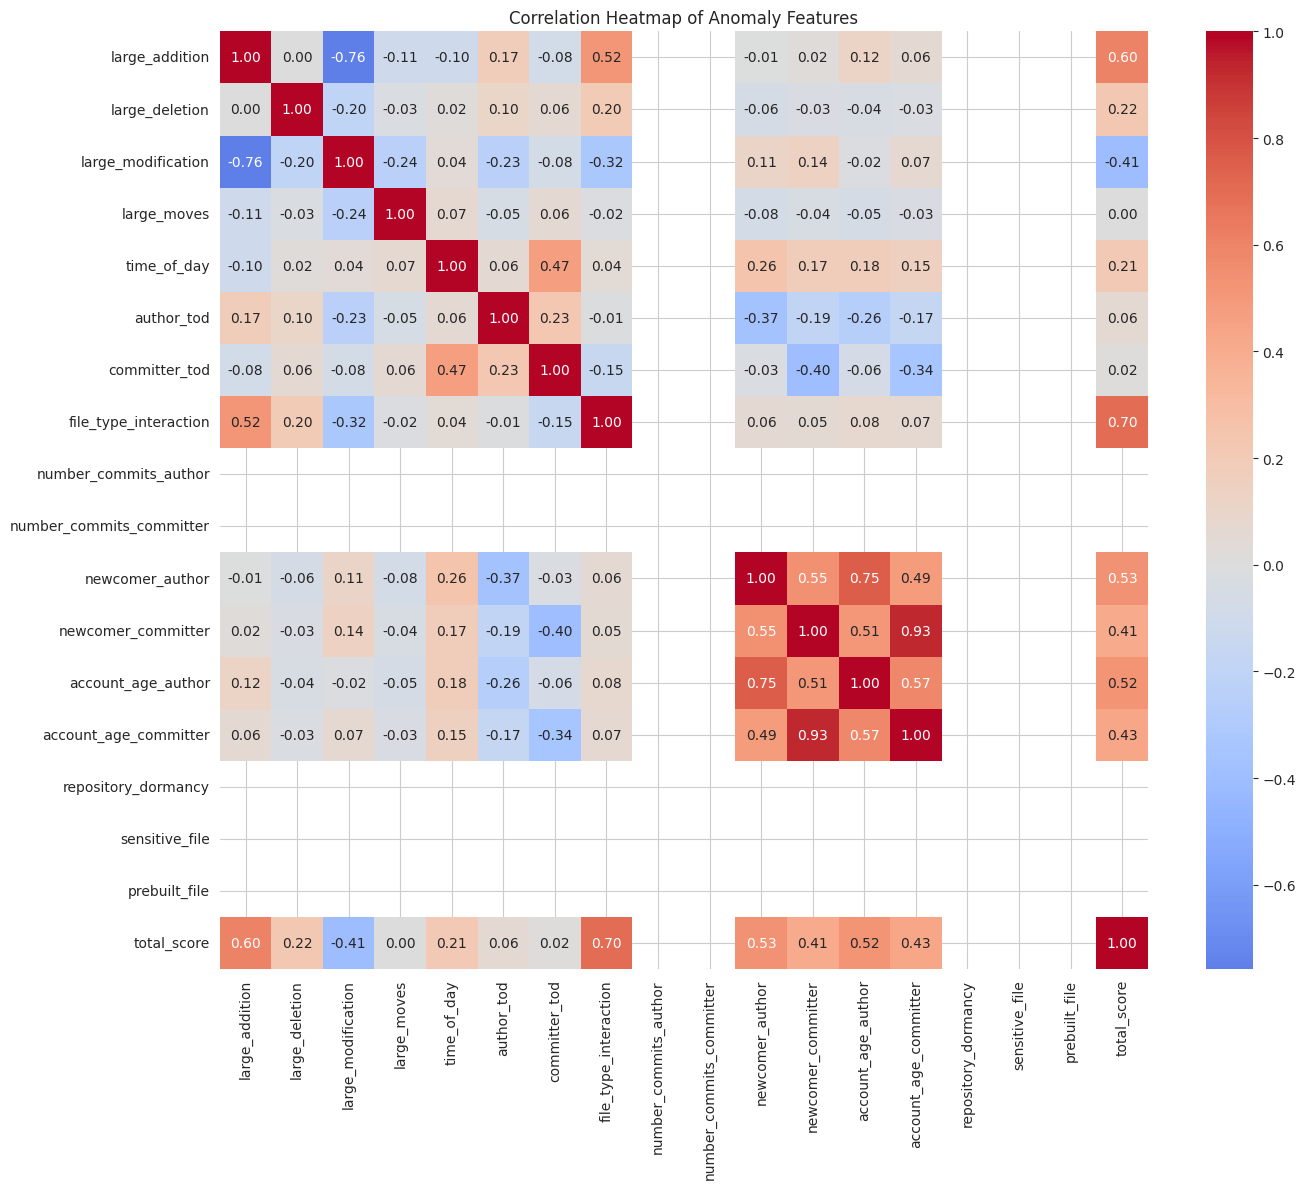

In [7]:
# Correlation heatmap of anomaly features
anomaly_columns = [
    'large_addition', 'large_deletion', 'large_modification', 'large_moves',
    'time_of_day', 'author_tod', 'committer_tod',
    'file_type_interaction', 'number_commits_author', 'number_commits_committer',
    'newcomer_author', 'newcomer_committer', 'account_age_author', 'account_age_committer',
    'repository_dormancy', 'sensitive_file', 'prebuilt_file', 'total_score'
]

plt.figure(figsize=(14, 12))
correlation_matrix = df[anomaly_columns].corr()
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Anomaly Features')
plt.tight_layout()
plt.show()

In [ ]:
# Analyze commits with high specific anomaly indicators
high_addition = df[df['large_addition'] > 0.8]
high_deletion = df[df['large_deletion'] > 0.8]
high_sensitive = df[df['sensitive_file'] > 0.5]

print(f"Commits with large additions: {len(high_addition)}")
print(f"Commits with large deletions: {len(high_deletion)}")
print(f"Commits with sensitive files: {len(high_sensitive)}")

Commits with large additions: 11
Commits with large deletions: 4
Commits with sensitive files: 0


In [ ]:
# Close connection
conn.close()